In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df = pd.read_csv("../data/housing.csv")

In [50]:
df.shape

(20640, 10)

In [51]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')

In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [53]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

the only column containig missing calues is total_bedrooms, with 207 missing entries

In [54]:
df.duplicated().sum()

np.int64(0)

In [55]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


The dataset contains 20,640 rows and 10 columns.

The target variable is median_house_value.

The only column containing missing values is total_bedrooms with 207 missing records.

The dataset contains one categorical feature, ocean_proximity, and nine numerical features.

No duplicate rows were found.

Several numerical features, such as total_rooms and population, show large ranges, suggesting the presence of outliers.

In [56]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [57]:
df["median_house_value"].describe()

count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64

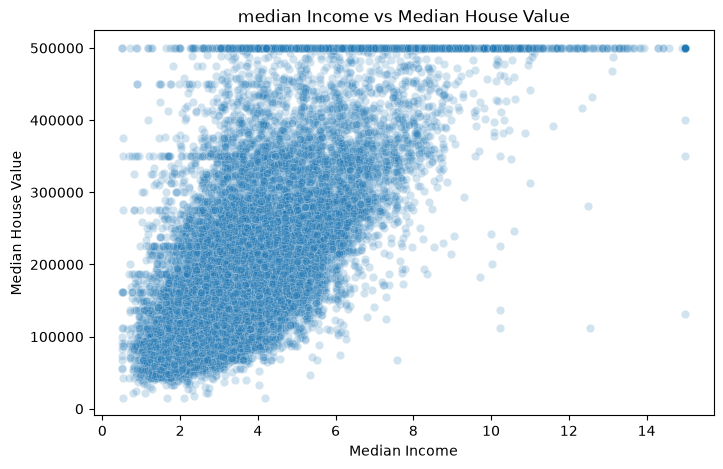

In [58]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.2
)
plt.title("median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.tight_layout
plt.show()

now let's separate features and target

In [59]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 9)
Target shape: (20640,)


In [60]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)


In [61]:
print("Training missing values:")
print(X_train.isnull().sum())

print("Testing missing values:")
print(X_test.isnull().sum())

Training missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64
Testing missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64


In [62]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=0.2, 
    random_state=42)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining missing values:")
print(X_train.isnull().sum())

print("\nTesting missing values:")
print(X_test.isnull().sum())

Training: (16512, 9)
Testing: (4128, 9)

Training missing values:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

Testing missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64


In [63]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Numerical pipeline
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [64]:
# Categorical pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [65]:
from sklearn.compose import ColumnTransformer

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [66]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (16512, 13)
Testing processed shape: (4128, 13)


Why 13 features?
Your original dataset had 9 input features:
- 8 numerical features.
- 1 categorical feature: ocean_proximity.
One-hot encoding converted that categorical feature into 5 binary columns.

Therefore:

8 numerical + 5 categorical = 13 processed features.

In [67]:
import numpy as np
print("Training contains NaN:", np.isnan(X_train_processed).any())
print("Testing contains NaN:", np.isnan(X_test_processed).any())

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training contains NaN: False
Testing contains NaN: False
Training shape: (16512, 13)
Testing shape: (4128, 13)


In [68]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [69]:
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

The outer Pipeline
At the top:

Pipeline

This connects two major components:
1. preprocessor — prepares the raw data.
2. LinearRegression — learns patterns and predicts house prices.
Why connect them? So that every time we train or predict, the same preprocessing operations happen automatically.
2. The Preprocessor
Your original dataset has 9 input features.

The ColumnTransformer separates them into two groups:
A. Numerical features — 8 features
These are:
- Longitude
- Latitude
- Housing median age
- Total rooms
- Total bedrooms
- Population
- Households
- Median income
They go through two operations:

SimpleImputer

Replaces missing numerical values using the median.

Why? Linear Regression cannot directly handle missing numerical values.

StandardScaler

Scales numerical features to comparable ranges.

Why? Features such as population and median income have very different numerical scales.
B. Categorical feature — 1 feature
This is:

ocean_proximity

It goes through:

SimpleImputer

Replaces missing categorical values using the most frequent category.

OneHotEncoder

Converts categories into numerical binary columns.

In [70]:
y_pred = model_pipeline.predict(X_test)

### Next: Let evaluate our model

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: $({mae:.2f})")
print(f"MSE: $({mse:.2f})")
print(f"RMSE: $({rmse:.2f})")
print(f"R²: $({r2:.2f})")

MAE: $(50670.49)
MSE: $(4908290571.35)
RMSE: $(70059.19)
R²: $(0.63)


In [72]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

comparison["Absolute Error"] = comparison["Error"].abs()

comparison.head(10)

,Actual,Predicted,Error,Absolute Error
0,47700.0,54261.027690,-6561.027690,6561.027690
1,45800.0,124430.917728,-78630.917728,78630.917728
2,500001.0,255694.958282,244306.041718,244306.041718
3,218600.0,268208.010360,-49608.010360,49608.010360
4,278000.0,262975.013606,15024.986394,15024.986394
5,158700.0,139811.882746,18888.117254,18888.117254
6,198200.0,290871.002705,-92671.002705,92671.002705
7,157500.0,228470.455166,-70970.455166,70970.455166
8,340000.0,256712.364401,83287.635599,83287.635599
9,446600.0,408129.437226,38470.562774,38470.562774


The actual value is $500,001, but the model predicts approximately $255,695.
Why might this happen?

Remember that our model assumes a linear relationship between the features and the target.

Real housing prices may have more complicated relationships.

For example, the effect of income on house prices might not remain constant across every income level.

In [73]:
comparison["Absolute Error"].describe()

count      4128.000000
mean      50670.489236
std       48387.594296
min          30.952644
25%       17950.871396
50%       38346.431888
75%       67304.689695
max      464817.768810
Name: Absolute Error, dtype: float64

Next experiment: Actual vs Predicted

We want to visually inspect how closely predictions follow actual values.

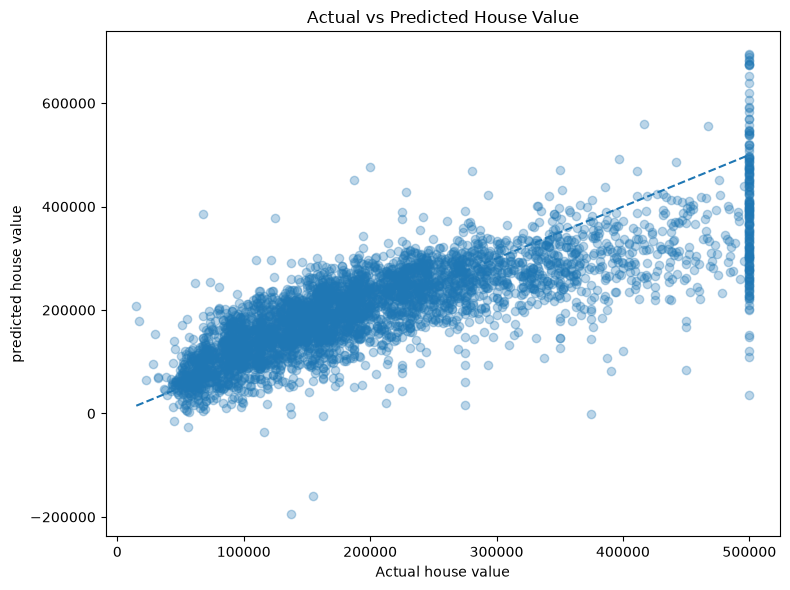

In [74]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)
plt.xlabel("Actual house value")
plt.ylabel("predicted house value")
plt.title("Actual vs Predicted House Value")

plt.tight_layout()
plt.savefig("../assets/actual_vs_predicted.png", dpi=300)
plt.show()

understand the diagonal line

The dashed diagonal represents perfect predictions.

If a district's actual house value is $200,000, a perfect model predicts $200,000.

Therefore:
- Points ON the line → perfect predictions.
- Points ABOVE the line → overestimation.
- Points BELOW the line → underestimation.

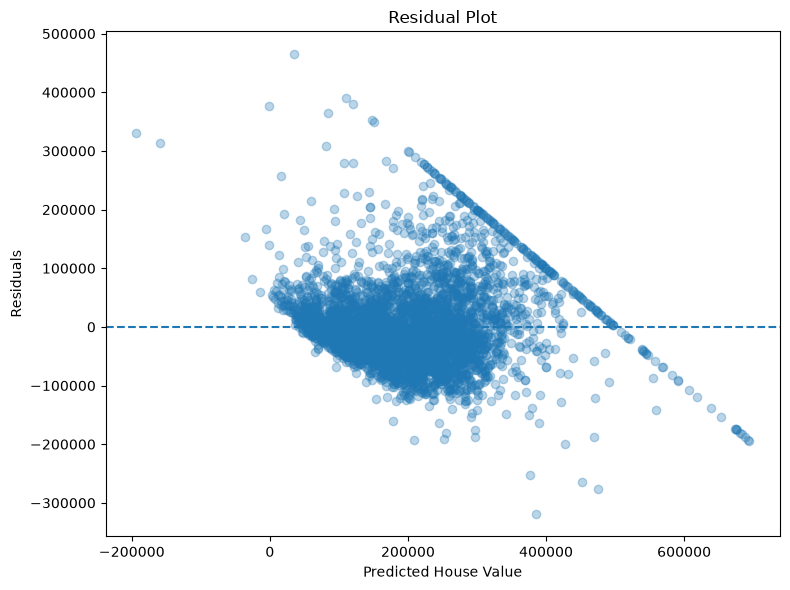

In [75]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.3)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Value")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.tight_layout()
plt.savefig("../assets/residual_plot.png", dpi=300)
plt.show()

### Next: Feature engineering
This is feature engineering: transforming existing data into more informative features.
We'll investigate three features:
1. rooms_per_household
2. bedrooms_per_room
3. population_per_household

In [76]:
import numpy as np
from sklearn.preprocessing import FunctionTransformer

def add_features(X):
    X = X.copy()

    X["rooms_per_household"] = (
        X["total_rooms"] / X["households"]
    )

    X["bedrooms_per_room"] = (
        X["total_bedrooms"] / X["total_rooms"]
    )

    X["population_per_household"] = (
        X["population"] / X["households"]
    )

    return X

feature_adder = FunctionTransformer(add_features)

In [77]:
print("Zero households:", (X_train["households"] == 0).sum())
print("Zero total rooms:", (X_train["total_rooms"] == 0).sum())

Zero households: 0
Zero total rooms: 0


In [78]:
numerical_pipeline = Pipeline([
    ("feature_engineering", feature_adder),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

Feature engineering creates three new columns.
Imputation handles missing values in all numerical columns.
Scaling puts numerical features on comparable scales.

In [79]:
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [80]:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [81]:
model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE: ${mae:,.2f}")
print(f"MSE: {mse:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R²: {r2:.4f}")


MAE: $49,645.49
MSE: 4,778,547,424.03
RMSE: $69,127.04
R²: 0.6353


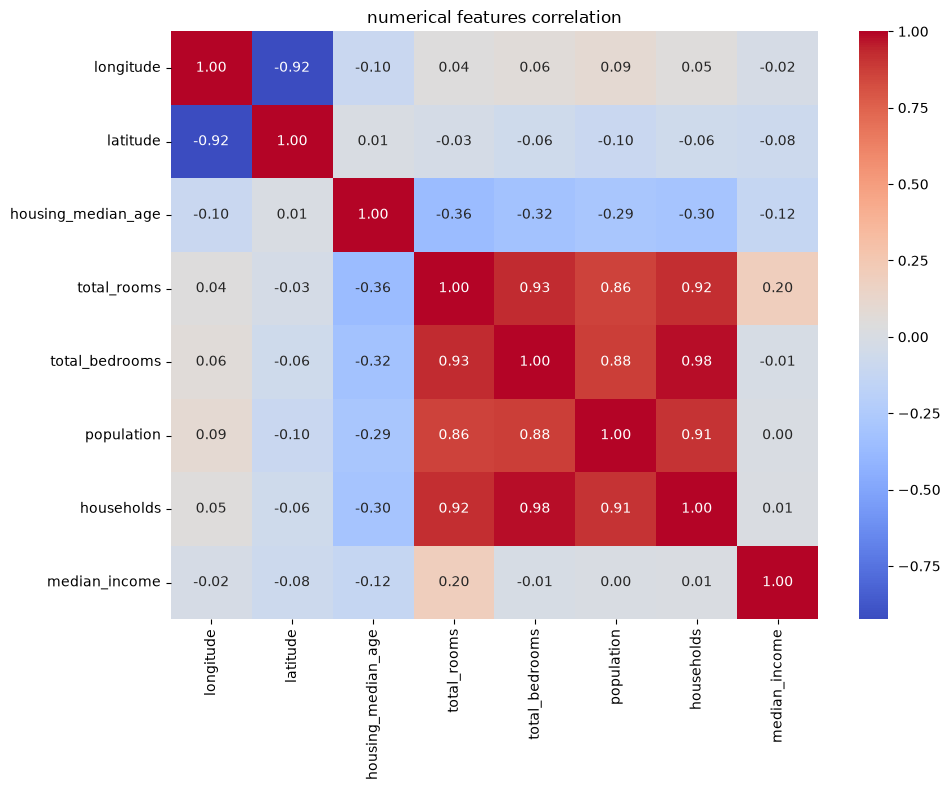

In [82]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation = X_train.select_dtypes(include="number").corr()
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("numerical features correlation")
plt.tight_layout()
plt.savefig("../assets/correlation_matrix.png", dpi=300)
plt.show()

### Correlation Analysis and Multicollinearity

The correlation heatmap reveals strong positive relationships among several numerical features. In particular, `total_bedrooms` and `households` have a correlation of 0.98, while `total_rooms` is strongly correlated with both `total_bedrooms` (0.93) and `households` (0.92).

These relationships suggest potential multicollinearity because several features may contain overlapping information about district size.

Multicollinearity can make individual regression coefficients unstable and difficult to interpret. However, high correlation alone does not justify removing features, since they may still contribute useful predictive information.

To investigate this issue further, we will calculate the Variance Inflation Factor (VIF) and evaluate whether regularization techniques such as Ridge and Lasso Regression improve model performance.

In [83]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [84]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import numpy as np

# Use numerical training features
X_vif = X_train.select_dtypes(include="number").copy()

# Impute missing values before calculating VIF
X_vif = X_vif.fillna(X_vif.median())

vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

display(vif_data)

,Feature,VIF
4,total_bedrooms,36.307087
6,households,35.824564
3,total_rooms,12.821807
1,latitude,8.798267
0,longitude,8.681823
5,population,6.345431
7,median_income,1.740998
2,housing_median_age,1.257629


Variance Inflation Factor (VIF) Analysis
VIF was calculated to investigate multicollinearity among numerical predictor variables. The results reveal substantial multicollinearity among total_bedrooms (36.31), households (35.82), and total_rooms (12.82). This suggests that these features contain overlapping information, particularly regarding district size.

Latitude, longitude, and population also show elevated VIF values. However, high VIF alone does not justify removing a feature because correlated variables may still contain useful predictive information.

To address potential coefficient instability, we will investigate regularization techniques, particularly Ridge and Lasso Regression, and compare their performance using cross-validation.

What is VIF?

VIF stands for Variance Inflation Factor.

It measures how strongly one feature can be explained by the other predictor features.

In other words:
VIF helps us identify which features have a multicollinearity problem.

 

How do we interpret VIF?

These are common guidelines, not universal laws:
VIF	Interpretation

1	No linear relationship with the other predictors
1–5	Usually acceptable

5–10	Potential multicollinearity concern

Above 10	Strong multicollinearity concern


A high VIF is a warning to investigate, not an automatic instruction to delete a feature.

In [85]:
from sklearn.linear_model import Ridge
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])
ridge_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

In [86]:
ridge_predictions = ridge_pipeline.predict(X_test)

### Evaluate the model

In [87]:
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)
ridge_r2 = r2_score(y_test, ridge_predictions)
print(f"MAE: ${ridge_mae:,.2f}")
print(f"RMSE: ${ridge_rmse:,.2f}")
print(f"R²: {ridge_r2:.2f}") 


MAE: $49,652.14
RMSE: $69,134.97
R²: 0.64


### Next: GridSearchCv

What problem does GridSearchCV solve?

We have a Ridge model:
Ridge(alpha=1.0)


But we don't know whether alpha=1.0 is the best choice.

We could manually train six different models:

Ridge(alpha=0.01)

Ridge(alpha=0.1)

Ridge(alpha=1)

Ridge(alpha=10)

Ridge(alpha=100)

Ridge(alpha=1000)


But this becomes repetitive.

GridSearchCV automates this process.

It:
1. Receives a list of hyperparameter values.
2. Trains and evaluates models using cross-validation.
3. Compares their average validation performance.
4. Identifies the best hyperparameter combination.
5. Refits the best estimator on the complete training dataset by default.
2. Understand the name
- Grid: The collection of hyperparameter combinations we want to test.
- Search: Systematically tests those combinations.
- CV: Uses cross-validation to evaluate them.

In [88]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "model__alpha": [0.01, 0.1, 1, 1.0, 10, 100, 1000]
}


Why "model__alpha" instead of simply "alpha"?

Remember our pipeline:

ridge_pipeline

    |

    |-- preprocessor

    |

    |-- model

          |

          |-- alpha

Scikit-learn uses double underscores (__) to access parameters inside pipeline steps.

Therefore:

model__alpha means the alpha parameter inside the pipeline's model step.

In [89]:
ridge_grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
ridge_grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...l', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

In [90]:
print("Best Alpha:", ridge_grid_search.best_params_)

print(
    "Best Cross-Validation RMSE:",
    -ridge_grid_search.best_score_
)
best_ridge_model = ridge_grid_search.best_estimator_

Best Alpha: {'model__alpha': 1}
Best Cross-Validation RMSE: 67847.58552226017


In [91]:
from sklearn.linear_model import Lasso
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])
lasso_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

In [92]:
lasso_predictions = lasso_pipeline.predict(X_test)

In [93]:
lasso_mae = mean_absolute_error(y_test, lasso_predictions)

lasso_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_predictions)
)

lasso_r2 = r2_score(y_test, lasso_predictions)

print("Lasso Regression Results")
print("------------------------")
print(f"MAE:  ${lasso_mae:,.2f}")
print(f"RMSE: ${lasso_rmse:,.2f}")
print(f"R²:    {lasso_r2:.4f}")

Lasso Regression Results
------------------------
MAE:  $49,646.43
RMSE: $69,128.09
R²:    0.6353


In [95]:
numerical_pipeline = Pipeline([
    ("feature_engineering", feature_adder),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

lasso_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

In [96]:
def feature_names_out(transformer, input_features):
    return np.asarray(list(input_features) + [
        "rooms_per_household",
        "bedrooms_per_room",
        "population_per_household"
    ], dtype=object)


feature_adder = FunctionTransformer(
    func=add_features,
    feature_names_out=feature_names_out,
    validate=False
)

In [97]:
print(feature_adder)
print(feature_adder.get_feature_names_out(
    numerical_features
))

FunctionTransformer(feature_names_out=<function feature_names_out at 0x00000136D502E560>,
                    func=<function add_features at 0x00000136D1926610>)
['longitude' 'latitude' 'housing_median_age' 'total_rooms'
 'total_bedrooms' 'population' 'households' 'median_income'
 'rooms_per_household' 'bedrooms_per_room' 'population_per_household']


In [98]:
print(feature_adder.get_feature_names_out(
    numerical_features
))

['longitude' 'latitude' 'housing_median_age' 'total_rooms'
 'total_bedrooms' 'population' 'households' 'median_income'
 'rooms_per_household' 'bedrooms_per_room' 'population_per_household']


In [100]:
numerical_pipeline = Pipeline([
    ("feature_engineering", feature_adder),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(alpha=1.0, max_iter=10000))
])

lasso_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

In [101]:
feature_names = lasso_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

lasso_coefficients = lasso_pipeline.named_steps[
    "model"
].coef_

lasso_feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_coefficients
})

lasso_feature_importance["Absolute_Coefficient"] = (
    lasso_feature_importance["Coefficient"].abs()
)

display(
    lasso_feature_importance.sort_values(
        by="Absolute_Coefficient",
        ascending=True
    )
)

,Feature,Coefficient,Absolute_Coefficient
11,categorical__ocean_proximity_<1H OCEAN,0.000000,0.000000
10,numerical__population_per_household,747.970856,747.970856
15,categorical__ocean_proximity_NEAR OCEAN,2996.153793,2996.153793
4,numerical__total_bedrooms,5328.247169,5328.247169
14,categorical__ocean_proximity_NEAR BAY,-5424.170186,5424.170186
3,numerical__total_rooms,5872.433840,5872.433840
8,numerical__rooms_per_household,7696.088159,7696.088159
2,numerical__housing_median_age,14121.444514,14121.444514
9,numerical__bedrooms_per_room,16805.912778,16805.912778
12,categorical__ocean_proximity_INLAND,-34955.884303,34955.884303


In [102]:
lasso_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

lasso_grid_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid_search.fit(X_train, y_train)

print("Best Alpha:", lasso_grid_search.best_params_)
print("Best CV RMSE:", -lasso_grid_search.best_score_)

Best Alpha: {'model__alpha': 1}
Best CV RMSE: 67848.71226030537


In [103]:
best_lasso_model = lasso_grid_search.best_estimator_

lasso_final_predictions = best_lasso_model.predict(X_test)

print("Final Test RMSE:",
      np.sqrt(mean_squared_error(y_test, lasso_final_predictions)))

print("Final Test MAE:",
      mean_absolute_error(y_test, lasso_final_predictions))

print("Final Test R2:",
      r2_score(y_test, lasso_final_predictions))

Final Test RMSE: 69128.09124072836
Final Test MAE: 49646.42889325855
Final Test R2: 0.6353281244301753


In [104]:
print("Ridge MAE:", mean_absolute_error(y_test, ridge_predictions))
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_test, ridge_predictions)))
print("Ridge R2:", r2_score(y_test, ridge_predictions))

Ridge MAE: 49652.14287272517
Ridge RMSE: 69134.96527371781
Ridge R2: 0.6352555955611363


In [105]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

In [106]:
random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [107]:
random_forest_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

In [108]:
rf_predictions = random_forest_pipeline.predict(X_test)

In [109]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R2:", rf_r2)

Random Forest MAE: 31766.87261264535
Random Forest RMSE: 49499.51559558054
Random Forest R2: 0.8130200506191368


In [110]:
# Predictions on training data
rf_train_predictions = random_forest_pipeline.predict(X_train)

# Training performance
rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, rf_train_predictions)
)

rf_train_r2 = r2_score(
    y_train,
    rf_train_predictions
)

# Test performance
rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_test_r2 = r2_score(
    y_test,
    rf_predictions
)

print("Training RMSE:", rf_train_rmse)
print("Test RMSE:", rf_test_rmse)

print("Training R2:", rf_train_r2)
print("Test R2:", rf_test_r2)

Training RMSE: 18270.2050848671
Test RMSE: 49499.51559558054
Training R2: 0.9750294857516959
Test R2: 0.8130200506191368


In [111]:
from sklearn.ensemble import RandomForestRegressor
regularized_rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

In [112]:
regularized_rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['longitude','latitude','housing_median_age',...,'households', 'median_income','ocean_proximity']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

### Evaluate

In [113]:
regularized_train_predictions = (
    regularized_rf_pipeline.predict(X_train)
)

regularized_test_predictions = (
    regularized_rf_pipeline.predict(X_test)
)

print(
    "Training RMSE:",
    np.sqrt(mean_squared_error(
        y_train, regularized_train_predictions
    ))
)

print(
    "Test RMSE:",
    np.sqrt(mean_squared_error(
        y_test, regularized_test_predictions
    ))
)

print(
    "Training R2:",
    r2_score(y_train, regularized_train_predictions)
)

print(
    "Test R2:",
    r2_score(y_test, regularized_test_predictions)
)

Training RMSE: 33437.84083144322
Test RMSE: 50082.949633678414
Training R2: 0.9163594087928585
Test R2: 0.8085863355899219


 
A. Training performance got worse.

Training RMSE increased from $18,270 to $33,438.

Why? We restricted the trees. They became less flexible, so they couldn't fit the training data as closely.

B. Test performance also got slightly worse.

Test RMSE increased from $49,500 to $50,083.

That means our regularization settings were too restrictive to improve generalization in this experiment.

C. The overfitting gap narrowed.
- Original R² gap: 0.9750 - 0.8130 = 0.1620
- Regularized R² gap: 0.9164 - 0.8086 = 0.1078
The gap decreased, but that alone doesn't mean the model became better. We need to consider test performance too.

# Next: RandomizedSearchCV for Random Forest

In [114]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from scipy.stats import randint

param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": randint(2, 20),
    "model__min_samples_leaf": randint(1, 10),
    "model__max_features": ["sqrt", 0.7, 1.0]
}

In [115]:
cv_strategy = KFold(
    n_splits = 5,
    shuffle=True,
    random_state=42
)

In [116]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

In [117]:
print("Pipeline:", random_forest_pipeline)
print("Training features:", X_train.shape)
print("Training target:", y_train.shape)
print("Parameter search space:", param_distributions)

Pipeline: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('feature_engineering',
                                                                   FunctionTransformer(feature_names_out=<function feature_names_out at 0x00000136D502E560>,
                                                                                       func=<function add_features at 0x00000136D1926610>)),
                                                                  ('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
            

In [118]:
random_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 10, ...], 'model__max_features': ['sqrt', 0.7, ...], 'model__min_samples_leaf': <scipy.stats....00136D5318410>, 'model__min_samples_split': <scipy.stats....00136D480A660>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where 

In [119]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)

Best Parameters:
{'model__max_depth': 30, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 3, 'model__min_samples_split': 6, 'model__n_estimators': 300}

Best Cross-Validation RMSE:
49893.452605276405


In [120]:
best_rf_model = random_search.best_estimator_

In [121]:
best_rf_train_predictions = best_rf_model.predict(X_train)

best_rf_train_rmse = np.sqrt(
    mean_absolute_error(y_train, best_rf_train_predictions)
)
best_rf_train_r2 = r2_score(
    y_train,
    best_rf_train_predictions
)
print("Training RMSE:", best_rf_train_rmse)
print("Training R2:", best_rf_train_r2)

Training RMSE: 139.8906149827696
Training R2: 0.9312626052720279


In [122]:
print("Actual target:")
print(y_train.describe())

print("\nPredictions:")
print(pd.Series(best_rf_train_predictions).describe())

print("\nFirst 10 actual values:")
print(y_train.head(10).values)

print("\nFirst 10 predictions:")
print(best_rf_train_predictions[:10])

Actual target:
count     16512.000000
mean     207194.693738
std      115622.626448
min       14999.000000
25%      119800.000000
50%      179850.000000
75%      265125.000000
max      500001.000000
Name: median_house_value, dtype: float64

Predictions:
count     16512.000000
mean     207321.897268
std      102966.333943
min       46959.185739
25%      129042.017535
50%      186761.727922
75%      262702.060016
max      499651.942151
dtype: float64

First 10 actual values:
[103000. 382100. 172600.  93400.  96500. 264800. 157300. 500001. 139800.
 315600.]

First 10 predictions:
[116571.16081049 370573.97607705 213117.36728632  90960.70310338
 104556.98902116 277984.42599048 166646.8412683  454063.20498653
 170692.95563363 309388.24370339]


In [123]:
print("Model training score (R2):", best_rf_model.score(X_train, y_train))

print(
    "Manually calculated R2:",
    r2_score(y_train, best_rf_train_predictions)
)


Model training score (R2): 0.9312626052720279
Manually calculated R2: 0.9312626052720279


In [124]:
# Calculate everything directly from the same arrays

errors = y_train.to_numpy() - best_rf_train_predictions

print("Number of observations:", len(errors))
print("MAE:", np.mean(np.abs(errors)))
print("RMSE:", np.sqrt(np.mean(errors ** 2)))
print("R2:", r2_score(y_train, best_rf_train_predictions))

print("\nFirst 10 errors:")
print(errors[:10])

Number of observations: 16512
MAE: 19569.384160257483
RMSE: 30312.811088304337
R2: 0.9312626052720279

First 10 errors:
[-13571.16081049  11526.02392295 -40517.36728632   2439.29689662
  -8056.98902116 -13184.42599048  -9346.8412683   45937.79501347
 -30892.95563363   6211.75629661]


In [125]:
best_rf_test_predictions = best_rf_model.predict(X_test)

final_mae = mean_absolute_error(
    y_test, best_rf_test_predictions
)

final_rmse = np.sqrt(mean_squared_error(
    y_test, best_rf_test_predictions
))

final_r2 = r2_score(
    y_test, best_rf_test_predictions
)

print("Final Test MAE:", final_mae)
print("Final Test RMSE:", final_rmse)
print("Final Test R2:", final_r2)

Final Test MAE: 32538.544703904958
Final Test RMSE: 49189.77790719558
Final Test R2: 0.8153527417213398


In [126]:
feature_names = best_rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_importances = (
    best_rf_model.named_steps["model"].feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
}).sort_values(
    by="Importance",
    ascending=False
)

importance_df

,Feature,Importance
7,numerical__median_income,0.303405
12,categorical__ocean_proximity_INLAND,0.146519
10,numerical__population_per_household,0.101391
9,numerical__bedrooms_per_room,0.094898
0,numerical__longitude,0.080672
1,numerical__latitude,0.073719
8,numerical__rooms_per_household,0.062475
2,numerical__housing_median_age,0.038259
11,categorical__ocean_proximity_<1H OCEAN,0.019418
3,numerical__total_rooms,0.018266


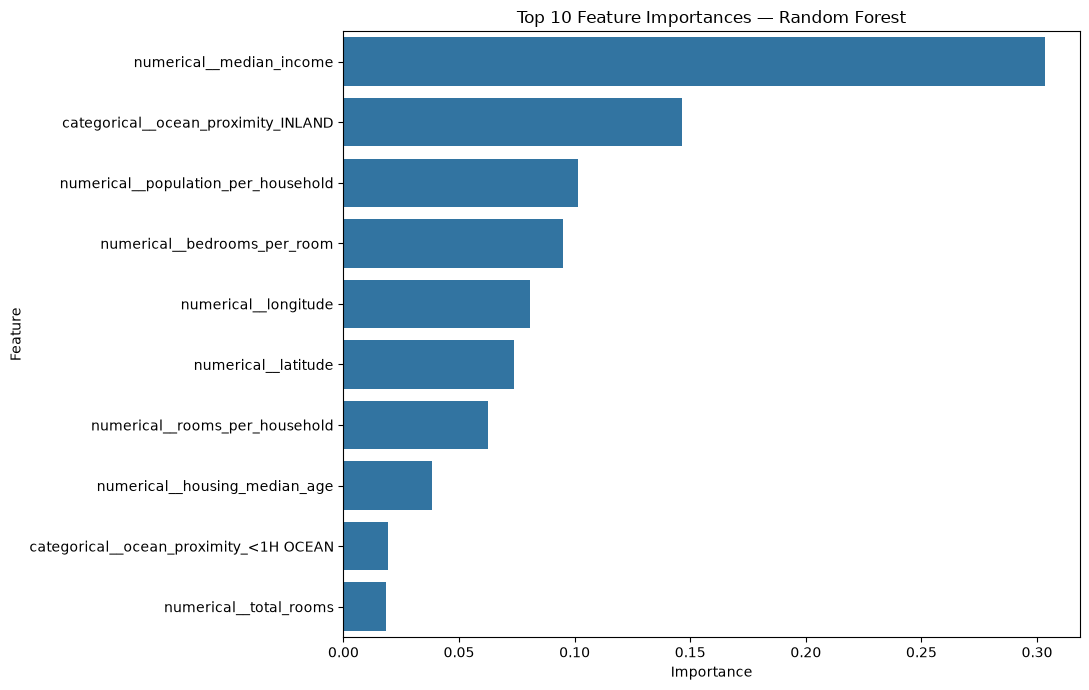

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 7))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()

plt.savefig(
    "../assets/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

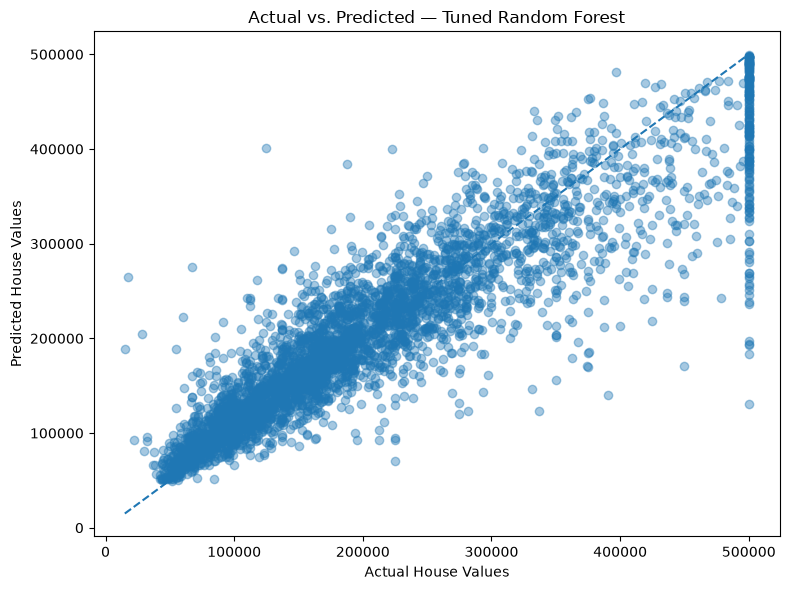

In [128]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_rf_test_predictions,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs. Predicted — Tuned Random Forest")

plt.tight_layout()

plt.savefig(
    "../assets/random_forest_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

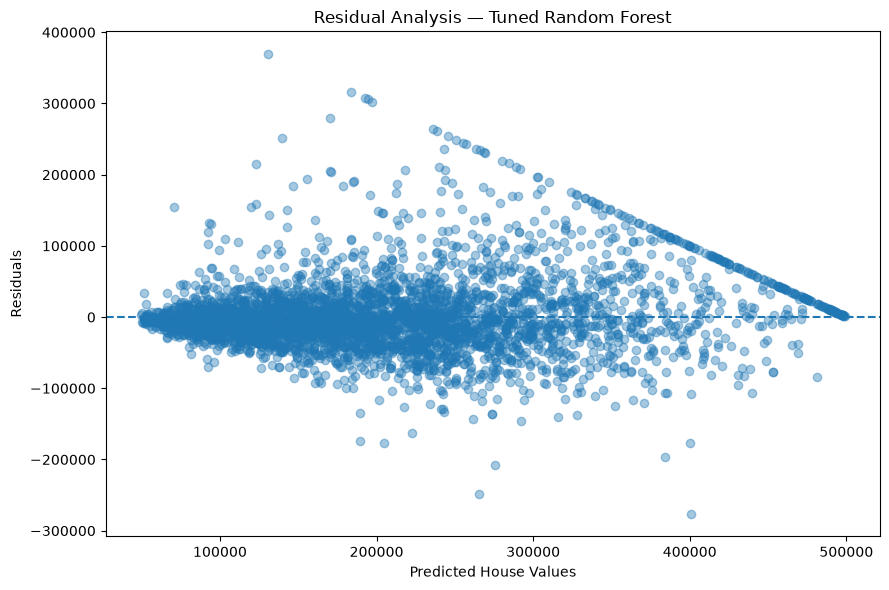

In [129]:
residuals = y_test - best_rf_test_predictions

plt.figure(figsize=(9, 6))

plt.scatter(
    best_rf_test_predictions,
    residuals,
    alpha=0.4
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Values")
plt.ylabel("Residuals")
plt.title("Residual Analysis — Tuned Random Forest")

plt.tight_layout()
plt.savefig(
    "../assets/random_forest_residuals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [130]:
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model_results = [
    {
        "Model": "Linear Regression (Baseline)",
        "MAE": 50670.49,
        "RMSE": 70059.19,
        "R2": 0.63
    },
    {
        "Model": "Feature-Engineered Linear Regression",
        "MAE": 49645.49,
        "RMSE": 69127.04,
        "R2": 0.6353
    },
    {
        "Model": "Ridge Regression",
        "MAE": 49652.14,
        "RMSE": 69134.97,
        "R2": r2_score(y_test, ridge_predictions)
    },
    {
        "Model": "Lasso Regression",
        "MAE": 49646.43,
        "RMSE": 69128.09,
        "R2": 0.6353
    },
    {
        "Model": "Random Forest",
        "MAE": 31766.87,
        "RMSE": 49499.52,
        "R2": 0.8130
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": 32538.54,
        "RMSE": 49189.78,
        "R2": 0.8154
    }
]

comparison_df = pd.DataFrame(model_results)

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

comparison_df.round(4)

,Model,MAE,RMSE,R2
0,Tuned Random Forest,32538.54,49189.78,0.8154
1,Random Forest,31766.87,49499.52,0.8130
2,Feature-Engineered Linear Regression,49645.49,69127.04,0.6353
3,Lasso Regression,49646.43,69128.09,0.6353
4,Ridge Regression,49652.14,69134.97,0.6353
5,Linear Regression (Baseline),50670.49,70059.19,0.6300


In [131]:
comparison_df.to_csv(
    "../assets/model_comparison.csv",
    index=False
)

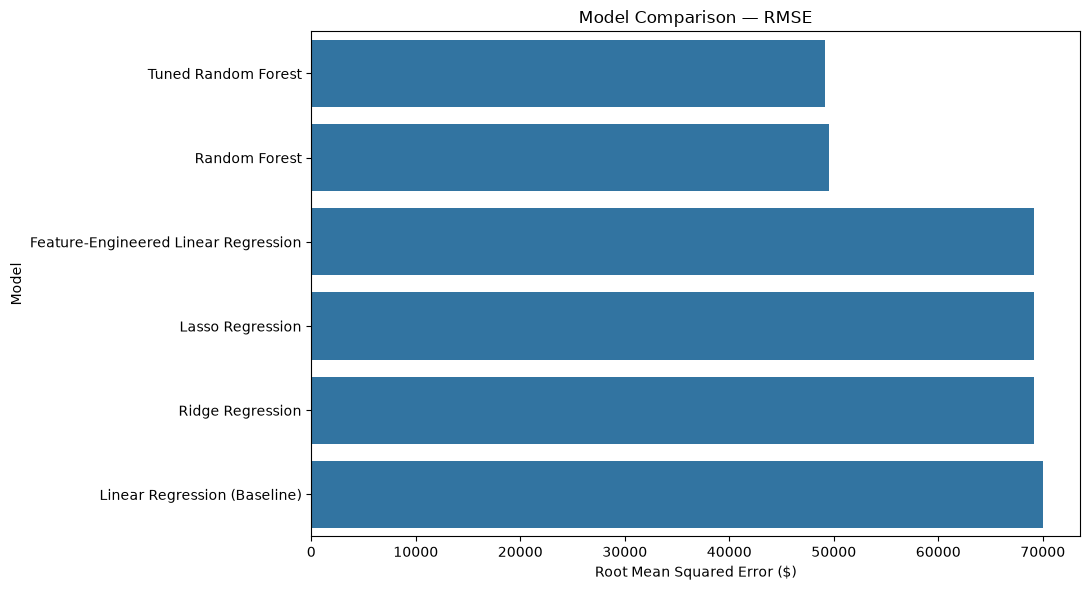

In [132]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="RMSE",
    y="Model"
)

plt.title("Model Comparison — RMSE")
plt.xlabel("Root Mean Squared Error ($)")
plt.ylabel("Model")

plt.tight_layout()

plt.savefig(
    "../assets/model_comparison_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

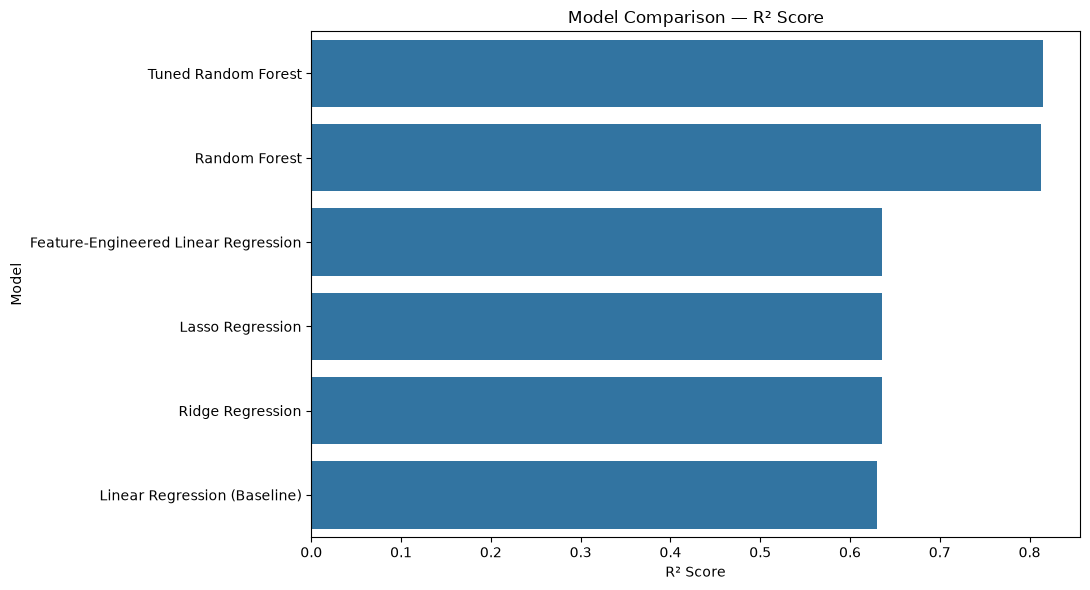

In [133]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="R2",
    y="Model"
)

plt.title("Model Comparison — R² Score")
plt.xlabel("R² Score")
plt.ylabel("Model")

plt.tight_layout()

plt.savefig(
    "../assets/model_comparison_r2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

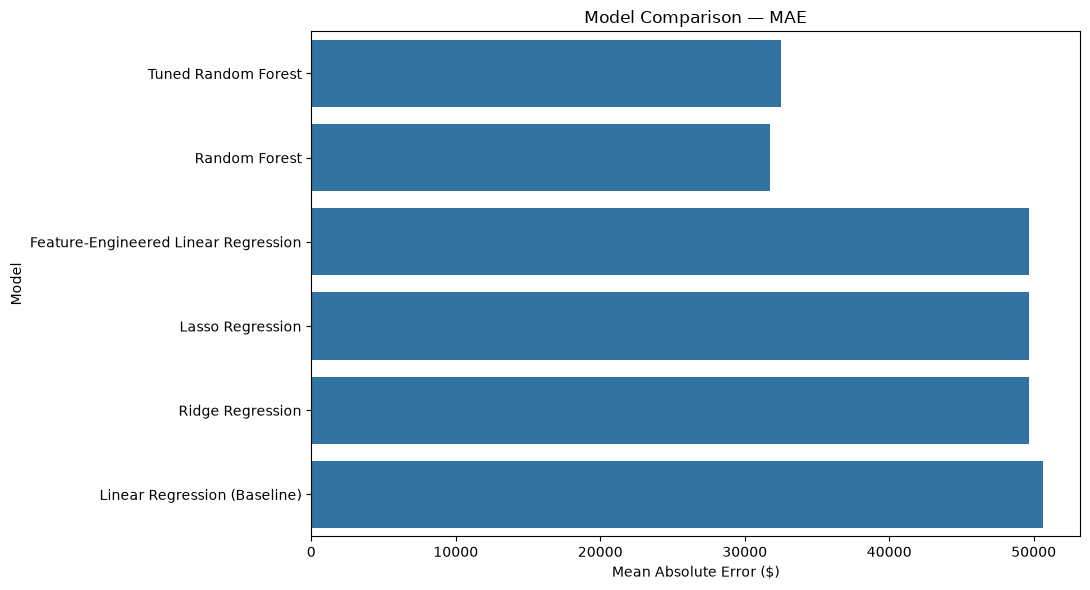

In [134]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_df,
    x="MAE",
    y="Model"
)

plt.title("Model Comparison — MAE")
plt.xlabel("Mean Absolute Error ($)")
plt.ylabel("Model")

plt.tight_layout()

plt.savefig(
    "../assets/model_comparison_mae.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()